In [1]:
import pyspark
import inflect
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *


spark = SparkSession.builder.appName('HW1_S1').getOrCreate()

In [ ]:
spark

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Loading the Dataset

In [3]:
df_init = spark.read.json('/content/drive/My Drive/Colab Datasets/train.json', multiLine=True)

In [ ]:
#df_init.printSchema()

In [ ]:
#df_init.toPandas()

#Preprocessing

Transforming  uppercase letters to lowercase

In [4]:
df = df_init.withColumn("ingredients", expr("transform(ingredients, x -> lower(x))"))
#df.toPandas()

In [ ]:
#df.filter(expr("exists(ingredients, x -> x rlike '[A-Z]')")).toPandas()
#no uppercase found

Removing every letter that is not in [a-z] like %,numbers and etc.

In [5]:
from pyspark.sql.functions import col, expr

# Apply regexp_replace to each word in the array
df = df.withColumn(
    "ingredients",
    expr("transform(ingredients, x -> regexp_replace(x, '[^a-z ]', ''))")
)

# df.toPandas()

Transforming each plural word to singular

In [6]:
from pyspark.sql.functions import col, udf
from pyspark.sql.types import ArrayType, StringType
import inflect

# Create an inflect engine
p = inflect.engine()

# Safe function to singularize words
def plural_to_singular_safe(word):
    try:
        if isinstance(word, str):  # Ensure the input is a string
            return p.singular_noun(word) or word
        return None  # Replace invalid entries with None
    except Exception as e:
        return None  # Handle unexpected errors gracefully

# Define a function to process a list of ingredients
def process_ingredients_safe(ingredients):
    if not isinstance(ingredients, list):  # Ensure the column is a list
        return []
    return [plural_to_singular_safe(ingredient) for ingredient in ingredients if ingredient]

# Register the safe UDF
singularize_udf_safe = udf(process_ingredients_safe, ArrayType(StringType()))

# Apply the safe UDF to the DataFrame
df_singularized_safe = df.withColumn("ingredients", singularize_udf_safe(col("ingredients")))

# Show the updated DataFrame
#df_singularized_safe.show(truncate=False)


Removing StopWords

In [7]:
# Define a list of stop words to remove
stop_words = {
    "ground", "black", "white", "red", "yellow", "green", "brown", "purple", "seed", "grated",
    "fresh", "chopped", "dried", "large", "small", "whole", "cooking", "powder", "boneless",
    "skinless", "crushed", "kosher", "toasted", "clove", "flake", "italian", "extract", "sea",
    "small", "medium", "large", "seasoning", "hot", "meal", "extravirgin", "leaf", "diced", "fat",
    "all","and", "extra", "in", "base", "salt", "pepper", "allpurpose", "water", "bell", "dry" , "shredded",
    "baking", "unsalted", "sodium", "frozen", "low", "heavy", "cooked", "half", "light", "sliced", "granulated",
    "freshly","free", "peeled", "baby", "reduced", "lowfat", "of", "mix", "finely", "allspice", "less", "slice",
    "sharp", "pure", "cracked", "active"
}

# Define a function to clean the ingredient names
def clean_ingredients(ingredients):
    # Remove stop words from each ingredient
    return [" ".join(word for word in ingredient.split() if word not in stop_words)
            for ingredient in ingredients]

# Register the function as a UDF
clean_ingredients_udf = udf(clean_ingredients, ArrayType(StringType()))

# Apply the UDF to the 'ingredients' column
df_stopwords = df_singularized_safe.withColumn("ingredients", clean_ingredients_udf(col("ingredients")))

# Show the result
#df_stopwords.toPandas()


Exploding the nested vector of ingredients into a string array of single words

In [8]:

# Split multi-word ingredients into unique words
df_exploded = df_stopwords.withColumn("ingredients", explode(col("ingredients")))
df_exploded = df_exploded.filter(col("ingredients") != "")
df_splited = df_exploded.withColumn("split_words", split(col("ingredients"), " "))

# Flatten the list of words
df_flat = df_splited.select("id", explode(col("split_words")).alias("word"))

# Get all unique words
unique_words = df_flat.select("word").distinct().collect()
word_list = [row["word"] for row in unique_words]

#print(word_list)
len(word_list)

#df_exploded.show()
#df_splited.show()

2816

#One-Hot Encoding

Defining a one-hot vector for each ID

In [ ]:
from pyspark.sql.functions import lit, max

# Add a binary "value" column to indicate ingredient presence
df_flat = df_flat.withColumn("value", lit(1))

# Pivot the DataFrame
df_one_hot = df_flat.groupBy("id").pivot("word").agg(
    max("value")  # Aggregate to ensure binary values
)

# Fill missing values with 0 (for ingredients not present in a food)
df_one_hot = df_one_hot.fillna(0)

In [ ]:
# Show the final one-hot encoded DataFrame
# df_one_hot.show(20,truncate=False)

Filtering the ingredients that are rarely used

In [ ]:
from pyspark.sql.functions import col, sum as _sum

# Calculate the sum for each ingredient column
ingredient_columns = [col_name for col_name in df_one_hot.columns if col_name != "id"]  # Exclude 'id' column
column_sums = df_one_hot.select(*[_sum(col(c)).alias(c) for c in ingredient_columns]).collect()[0].asDict()

# Filter columns based on the threshold
threshold = 20
selected_columns = [c for c, total in column_sums.items() if total >= threshold]

# Create a new DataFrame with filtered columns
df_oneHot_filtered = df_one_hot.select(["id"] + selected_columns)

# result
df_oneHot_filtered.show()

column_count = len(df_oneHot_filtered.columns)
print(f"The number of columns is: {column_count}")


+---+-------+-----+-----+---+-------+------+--------+------+--------+-----+-------+-----+-------+---------+-----+-----+-------+-----+----------+-------+-----+-------+---------+--------+---------+-------+-------+---------+----------+------+-----+--------+---------+-------+----+-----+---+--------+-----+--------+------+------+---+--------+------+---+-----+-------+----+------+---+---+----+----------+------+----+---------+----+----+-------+-------+-----+-----+--------+----+----+----+-------+--------+---+------+-----------+----------+---------+--------+-----+-----+-------+----+---------+----+-------+---+----+------+------+------+----+------+-------+------+--------+-------+-------+------+------+-----+----------+---------+------+------+----+-----+----------+-------+--------+----------+-----+--------+--------+---------+----+------+----+---+--------+----+------+---------------+----------+---------+------+-------+-------+-----+----+---------+----------+-------+---------+--------+-------+-----+---

Writing the result into a .csv file

In [ ]:
#df_oneHot_filtered.coalesce(1).write.mode("overwrite").csv('/content/drive/My Drive/Colab Datasets/df_oneHot_filtered', header=True)

In [12]:
df_oneHot_filtered= spark.read.csv('/content/drive/My Drive/Colab Datasets/df_oneHot_filtered/df_oneHot_filtered.csv', inferSchema = True, header = True)

#K-means Clustering using one-hot vectors

In [13]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans

using VectorAssembler to create a "features" vector for each id based on one_hot encoded ingredients

In [14]:
# Assemble all ingredient columns into a single feature vector
ingredient_columns = df_oneHot_filtered.columns[1:]  # Exclude the "id" column
assembler = VectorAssembler(inputCols=ingredient_columns, outputCol="features")

df_oneHot_features = assembler.transform(df_oneHot_filtered)
#df_oneHot_features.select("id", "features").show(20, truncate=False)

Converting sparse vector of features into aa dense vector of points(we need them for calculating wcss)

In [20]:
from pyspark.ml.linalg import Vectors, SparseVector, DenseVector

# Convert SparseVector to Dense Array before applying squared_distance
def sparse_to_array(sparse_vector):
    if isinstance(sparse_vector, SparseVector):
        return sparse_vector.toArray().tolist()  # Convert SparseVector to dense list
    elif isinstance(sparse_vector, DenseVector):
        return sparse_vector.tolist()  # Convert DenseVector to list
    return sparse_vector  # In case of unexpected types

# UDF to convert SparseVector to Dense Array
sparse_to_array_udf = udf(sparse_to_array, ArrayType(DoubleType()))

df_oneHot_features = df_oneHot_features.withColumn("points", sparse_to_array_udf(col("features")))

Sorting the words based on their varinace :
  we use this part to identify the words that have high variance but aren't related to foods, and adding them to the stopwords in the preprocessing section(this part is not in the main code, and it's part of the preprocessing)

In [ ]:
# from pyspark.ml.stat import Summarizer

# # Combine feature columns into a single vector column
# feature_columns = [col for col in df_oneHot_features.columns if col != 'id']

# # Calculate variance using Summarizer
# summarizer = Summarizer.metrics("variance")
# summary = df_oneHot_features.select(Summarizer.variance(df_oneHot_features["features"]).alias("variances"))

# # Extract variance as a list
# variances = summary.collect()[0]["variances"]

# # Map feature names to variances
# feature_variances = list(zip(feature_columns, variances))

# # Sort features by variance in descending order
# sorted_features = sorted(feature_variances, key=lambda x: x[1], reverse=True)

# # Print sorted features with their variances
# for feature, variance in sorted_features:
#     print(f"{feature}: {variance}")


In [ ]:
df_oneHot_features.show(20, truncate = False)

+---+-------+-----+-----+---+-------+------+--------+------+--------+-----+-------+-----+-------+---------+-----+-----+-------+-----+----------+-------+-----+-------+---------+--------+---------+-------+-------+---------+----------+------+-----+--------+---------+-------+----+-----+---+--------+-----+--------+------+------+---+--------+------+---+-----+-------+----+------+---+---+----+----------+------+----+---------+----+----+-------+-------+-----+-----+--------+----+----+----+-------+--------+---+------+-----------+----------+---------+--------+-----+-----+-------+----+---------+----+-------+---+----+------+------+------+----+------+-------+------+--------+-------+-------+------+------+-----+----------+---------+------+------+----+-----+----------+-------+--------+----------+-----+--------+--------+---------+----+------+----+---+--------+----+------+---------------+----------+---------+------+-------+-------+-----+----+---------+----------+-------+---------+--------+-------+-----+---

Using Elbow Method for finding the optimum k

In [ ]:
from pyspark.sql.functions import udf, col
from pyspark.sql.types import ArrayType, DoubleType
import numpy as np

ks = range(5,60,5)
wcss = []
for k in  ks:
    kmeans_oneHot= KMeans(k=k, seed=42, featuresCol="features")
    model_oneHot = kmeans_oneHot.fit(df_oneHot_features)

    # Assign clusters to data points
    predictions_oneHot = model_oneHot.transform(df_oneHot_features)

    # Get cluster centers
    centers_oneHot = model_oneHot.clusterCenters()
    bc_centers_oneHot = spark.sparkContext.broadcast(centers_oneHot)

    get_cluster_center_udf = udf(
            lambda cluster_id: bc_centers_oneHot.value[cluster_id].tolist(),
            ArrayType(DoubleType())
        )

    predictions_oneHot = predictions_oneHot.withColumn("centers",
          get_cluster_center_udf(col("prediction")))

    # Extract relevant columns as RDD
    rdd_data = predictions_oneHot.select("points", "centers").rdd

    # Calculate squared distances using map
    oneHot_sd_rdd = rdd_data.map(lambda row: np.sum((np.array(row["points"]) - np.array(row["centers"])) ** 2))

    # Compute the average squared distance
    oneHot_average_sd = oneHot_sd_rdd.mean()

    wcss.append(oneHot_average_sd)

    print(f"Average Squared Distance for {k} clusters: {oneHot_average_sd}")

Average Squared Distance for 5 clusters: 9.579975155456866
Average Squared Distance for 10 clusters: 9.136628172690834
Average Squared Distance for 15 clusters: 8.87210466242848
Average Squared Distance for 20 clusters: 8.717104444541906
Average Squared Distance for 25 clusters: 8.61652124518962
Average Squared Distance for 30 clusters: 8.4904095932724
Average Squared Distance for 35 clusters: 8.387861461990571
Average Squared Distance for 40 clusters: 8.327825201825412
Average Squared Distance for 45 clusters: 8.28114483892752
Average Squared Distance for 50 clusters: 8.210383582194751
Average Squared Distance for 55 clusters: 8.172858619775345


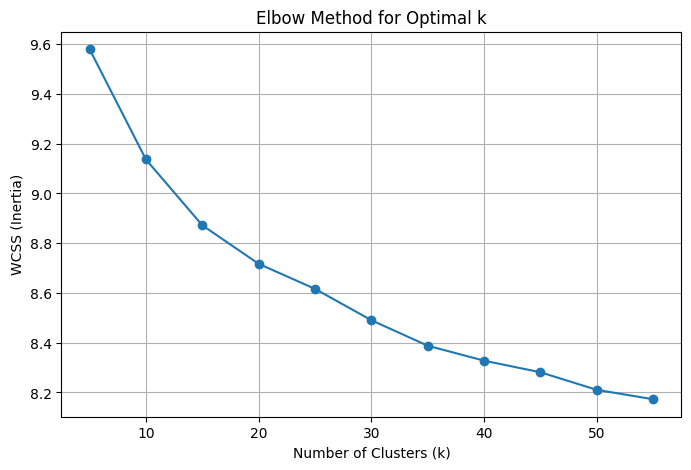

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(ks, wcss, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method for Optimal k")
plt.grid()
plt.show()

clustering the the dataset with the optimum number of k (we chose k=35 based on the graph)

In [21]:
from pyspark.sql.functions import udf, col
from pyspark.ml.clustering import KMeans
from pyspark.sql.types import ArrayType, DoubleType

kmeans_oneHot_final= KMeans(k=35, seed=42, featuresCol="features")
model_oneHot_final = kmeans_oneHot_final.fit(df_oneHot_features)

# Assign clusters to data points
predictions_oneHot_final = model_oneHot_final.transform(df_oneHot_features)
predictions_oneHot_final = predictions_oneHot_final.drop("points", "features")

In [ ]:
predictions_oneHot_final.show(20, truncate = False)

+---+-------+-----+-----+---+-------+------+--------+------+--------+-----+-------+-----+-------+---------+-----+-----+-------+-----+----------+-------+-----+-------+---------+--------+---------+-------+-------+---------+----------+------+-----+--------+---------+-------+----+-----+---+--------+-----+--------+------+------+---+--------+------+---+-----+-------+----+------+---+---+----+----------+------+----+---------+----+----+-------+-------+-----+-----+--------+----+----+----+-------+--------+---+------+-----------+----------+---------+--------+-----+-----+-------+----+---------+----+-------+---+----+------+------+------+----+------+-------+------+--------+-------+-------+------+------+-----+----------+---------+------+------+----+-----+----------+-------+--------+----------+-----+--------+--------+---------+----+------+----+---+--------+----+------+---------------+----------+---------+------+-------+-------+-----+----+---------+----------+-------+---------+--------+-------+-----+---

Finding the most 10 ingredients used in each cluster

In [22]:
from pyspark.sql import functions as F
from pyspark.sql import Window


# Group by the cluster label (e.g., prediction) and calculate the sum of all ingredient columns
feature_columns_oneHot = [col for col in predictions_oneHot_final.columns if col not in ['id', 'prediction']]  # Exclude non-feature columns

# Aggregate sum of each feature for each cluster
cluster_summary_oneHot = predictions_oneHot_final.groupBy("prediction").agg(
    *[F.sum(col).alias(col) for col in feature_columns_oneHot]
)

# Convert cluster_summary into a long format to rank ingredients
long_format_oneHot = cluster_summary_oneHot.select(
    F.col("prediction"),
    F.explode(F.array(
        *[F.struct(F.lit(col).alias("ingredient"), F.col(col).alias("count")) for col in feature_columns_oneHot]
    )).alias("ingredient_count")
).select(
    F.col("prediction"),
    F.col("ingredient_count.ingredient"),
    F.col("ingredient_count.count")
)

# Rank ingredients within each cluster by their counts
ranked_ingredients_oneHot = long_format_oneHot.withColumn(
    "rank",
    F.row_number().over(
        Window.partitionBy("prediction").orderBy(F.desc("count"))
    )
).filter(F.col("rank") <= 10)

In [16]:
# Display the results
ranked_ingredients_oneHot.toPandas()

,prediction,ingredient,count,rank
0,0,milk,734,1
1,0,cheese,728,2
2,0,flour,688,3
3,0,egg,616,4
4,0,butter,611,5
...,...,...,...,...
345,34,yolk,477,6
346,34,butter,464,7
347,34,whipping,332,8
348,34,chocolate,326,9


In [23]:
ranked_ingredients_oneHot.coalesce(1).write.mode("overwrite").csv('/content/drive/My Drive/Colab Datasets/ranked_ingredients_oneHot', header=True)

Number of datas in each cluster

In [ ]:
# Group by the 'prediction' column (cluster assignment) and count the number of rows in each cluster
cluster_counts_oneHot = predictions_oneHot_final.groupBy("prediction").count().orderBy("prediction")

# Show the result
cluster_counts_oneHot.toPandas()

,prediction,count
0,0,898
1,1,929
2,2,1275
3,3,1666
4,4,831
5,5,719
6,6,2540
7,7,664
8,8,901
9,9,772


#Word2Vec Encoding

Giving the ingredients of each id as a list of single words to the Word2Vec model

In [9]:
from pyspark.ml.feature import Word2Vec
from pyspark.sql.functions import col, expr, mean

#defining the dataset for the Word2Vec model
df_wrd2vec = df_flat.groupBy("id").agg(collect_list("word").alias("ingredients"))

# Initialize the Word2Vec model
word2vec = Word2Vec(
    vectorSize=100,  # Dimensionality of the word vectors
    minCount=1,      # Minimum frequency of words to include in the model
    inputCol="ingredients",
    outputCol="features"
)

# Train the Word2Vec model
word2vec_model = word2vec.fit(df_wrd2vec)

# Transform the DataFrame to get word embeddings for each food's ingredients
df_wrd2vec = word2vec_model.transform(df_wrd2vec)
df_wrd2vec.show(20, truncate= False)

+---+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

#K-means clustering using Word2Vec vectors

Finding the optimum k using the Elbow Method

In [ ]:
from pyspark.ml.clustering import KMeans

In [ ]:
from pyspark.sql.functions import udf, col
from pyspark.sql.types import ArrayType, DoubleType
import numpy as np

ks_wrd2vec = range(4,40,4)
wcss_wrd2vec = []
for k in  ks_wrd2vec:
    kmeans_wrd2vec= KMeans(k=k, seed=42, featuresCol="features")
    model_wrd2vec = kmeans_wrd2vec.fit(df_wrd2vec)

    # Assign clusters to data points
    predictions_wrd2vec = model_wrd2vec.transform(df_wrd2vec)

    # Get cluster centers
    centers_wrd2vec = model_wrd2vec.clusterCenters()
    bc_centers_wrd2vec = spark.sparkContext.broadcast(centers_wrd2vec)

    get_cluster_center_udf = udf(
            lambda cluster_id: bc_centers_wrd2vec.value[cluster_id].tolist(),
            ArrayType(DoubleType())
        )

    predictions_wrd2vec = predictions_wrd2vec.withColumn("centers",
          get_cluster_center_udf(col("prediction")))

    # Extract relevant columns as RDD
    rdd_data_wrd2vec = predictions_wrd2vec.select("features", "centers").rdd

    # Calculate squared distances using map
    wrd2vec_sd_rdd = rdd_data_wrd2vec.map(lambda row: np.sum((np.array(row["features"]) - np.array(row["centers"])) ** 2))

    # Compute the average squared distance
    wrd2vec_average_sd = wrd2vec_sd_rdd.mean()

    wcss_wrd2vec.append(wrd2vec_average_sd)

    print(f"Average Squared Distance for {k} clusters: {wrd2vec_average_sd}")

Average Squared Distance for 4 clusters: 0.4566369761735783
Average Squared Distance for 8 clusters: 0.35763429637986627
Average Squared Distance for 12 clusters: 0.3204194265739591
Average Squared Distance for 16 clusters: 0.2985902606716503
Average Squared Distance for 20 clusters: 0.28365143095028517
Average Squared Distance for 24 clusters: 0.2735596491792712
Average Squared Distance for 28 clusters: 0.2658060036847866
Average Squared Distance for 32 clusters: 0.26040412256394563
Average Squared Distance for 36 clusters: 0.2524641478898522


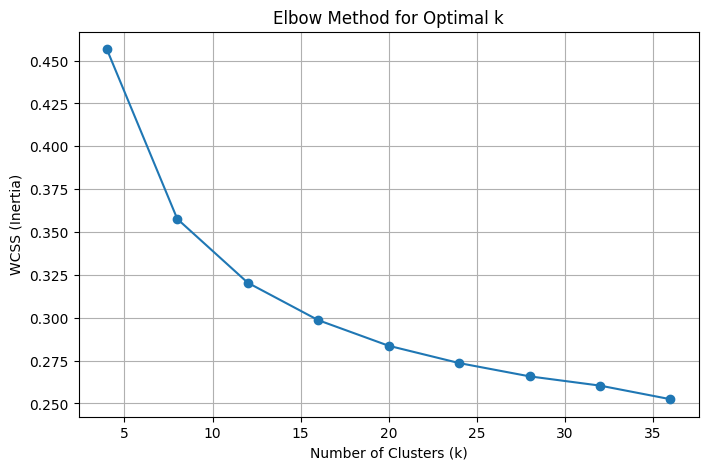

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(ks_wrd2vec, wcss_wrd2vec, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method for Optimal k")
plt.grid()
plt.show()

clustering the data with the optimum k (we chose k = 24 based on the graph)

In [10]:
from pyspark.ml.clustering import KMeans

kmeans_wrd2vec_final= KMeans(k=24, seed=42, featuresCol="features")
model_wrd2vec_final = kmeans_wrd2vec_final.fit(df_wrd2vec)

# Assign clusters to data points
predictions_wrd2vec_final = model_wrd2vec_final.transform(df_wrd2vec)

In [25]:
predictions_wrd2vec_final.show(20, truncate=False)

+---+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Combining the prediction results with the one-hot encoded dataset of the previous section.(we need it to count the most used words in each cluster)

In [15]:
predictions_wrd2vec_withIngredients = predictions_wrd2vec_final.drop("ingredients", "features")
df_oneHot_ingredients = df_oneHot_features.drop("points", "features")

# Join the two datasets based on the 'id' column
predictions_wrd2vec_withIngredients = predictions_wrd2vec_withIngredients.join(df_oneHot_ingredients, on="id", how="inner")

# Show the result
predictions_wrd2vec_withIngredients.show(20, truncate=False)


+---+----------+-------+-----+-----+---+-------+------+--------+------+--------+-----+-------+-----+-------+---------+-----+-----+-------+-----+----------+-------+-----+-------+---------+--------+---------+-------+-------+---------+----------+------+-----+--------+---------+-------+----+-----+---+--------+-----+--------+------+------+---+--------+------+---+-----+-------+----+------+---+---+----+----------+------+----+---------+----+----+-------+-------+-----+-----+--------+----+----+----+-------+--------+---+------+-----------+----------+---------+--------+-----+-----+-------+----+---------+----+-------+---+----+------+------+------+----+------+-------+------+--------+-------+-------+------+------+-----+----------+---------+------+------+----+-----+----------+-------+--------+----------+-----+--------+--------+---------+----+------+----+---+--------+----+------+---------------+----------+---------+------+-------+-------+-----+----+---------+----------+-------+---------+--------+------

Finding the most 10 used words in each cluster

In [16]:
from pyspark.sql import functions as F
from pyspark.sql import Window


# Group by the cluster label (e.g., prediction) and calculate the sum of all ingredient columns
feature_columns_wrd2vec = [col for col in predictions_wrd2vec_withIngredients.columns if col not in ['id', 'prediction']]  # Exclude non-feature columns

# Aggregate sum of each feature for each cluster
cluster_summary_wrd2vec = predictions_wrd2vec_withIngredients.groupBy("prediction").agg(
    *[F.sum(col).alias(col) for col in feature_columns_wrd2vec]
)

# Convert cluster_summary into a long format to rank ingredients
long_format_wrd2vec = cluster_summary_wrd2vec.select(
    F.col("prediction"),
    F.explode(F.array(
        *[F.struct(F.lit(col).alias("ingredient"), F.col(col).alias("count")) for col in feature_columns_wrd2vec]
    )).alias("ingredient_count")
).select(
    F.col("prediction"),
    F.col("ingredient_count.ingredient"),
    F.col("ingredient_count.count")
)

# Rank ingredients within each cluster by their counts
ranked_ingredients_wrd2vec = long_format_wrd2vec.withColumn(
    "rank",
    F.row_number().over(
        Window.partitionBy("prediction").orderBy(F.desc("count"))
    )
).filter(F.col("rank") <= 10)

In [17]:
# Display the results
ranked_ingredients_wrd2vec.toPandas()

,prediction,ingredient,count,rank
0,0,sauce,1952,1
1,0,soy,1815,2
2,0,oil,1581,3
3,0,sesame,1309,4
4,0,garlic,1110,5
...,...,...,...,...
235,23,cinnamon,529,6
236,23,lemon,370,7
237,23,juice,302,8
238,23,vanilla,300,9


In [24]:
ranked_ingredients_wrd2vec.coalesce(1).write.mode("overwrite").csv('/content/drive/My Drive/Colab Datasets/ranked_ingredients_wrd2vec', header=True)

Number of datas in each cluster

In [18]:
# Group by the 'prediction' column (cluster assignment) and count the number of rows in each cluster
cluster_counts_wrd2vec = predictions_wrd2vec_final.groupBy("prediction").count().orderBy("prediction")

# Show the result
cluster_counts_wrd2vec.toPandas()

,prediction,count
0,0,2239
1,1,413
2,2,1041
3,3,1149
4,4,1904
5,5,1500
6,6,2163
7,7,803
8,8,1621
9,9,1326
